# Medical Insurance Cost Prediction
**Domain:** Healthcare Analytics  |  **Task:** Regression  |  **Target:** `charges` (medical insurance cost)

Medical insurance cost differs from person to person. In this project we build a machine learning model that predicts
an individual's insurance charges from attributes such as age, BMI, smoking habit, number of children and region.



In [114]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (7, 4)
BLUE="#2a6fbb"
ORANGE="#d9822b"
SMOKER_COLORS={"no": BLUE, "yes": ORANGE}


## 1. Loading the data
We use the public **Medical Cost Personal Dataset** (1,338 records). It is the widely used `insurance.csv` file (origibally from the book *Machine Learning by Brett Lantz, also available on Kaggle.).

In [115]:
df = pd.read_csv("insurance.csv")

In [116]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [117]:
df.shape

(1338, 7)

In [118]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [119]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## 3. Exploratory Data Analysis (EDA)

**3.1 Distribution of insurance charges**

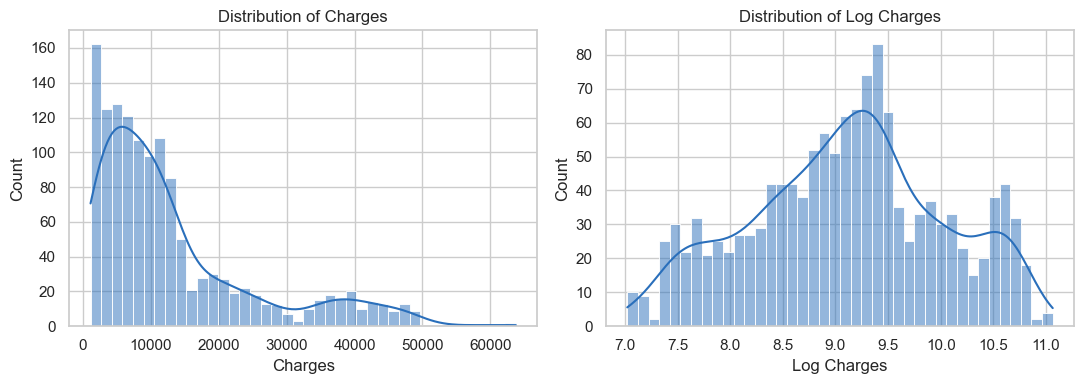

Skewness of Charges: 1.5158796580240388 2
Median charge: 9382.03 | Mean charge: 13270.42


In [120]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df["charges"],bins=40,kde=True,color=BLUE,ax=ax[0])
ax[0].set_title("Distribution of Charges")
ax[0].set_xlabel("Charges")

sns.histplot(np.log(df["charges"]),bins=40,kde=True,color=BLUE,ax=ax[1])
ax[1].set_title("Distribution of Log Charges")
ax[1].set_xlabel("Log Charges")

plt.tight_layout()
plt.show()

print("Skewness of Charges:", df["charges"].skew(),2)
print("Median charge:",round(df["charges"].median(),2),"| Mean charge:",round(df["charges"].mean(),2))



***Observation:*** Charges are strongly right-skewed.Most people pay a lower amount, while asmaller group pays very high amounts. The mean is higher than the media because of this long tail 

**3.2 Age Vs Charges**

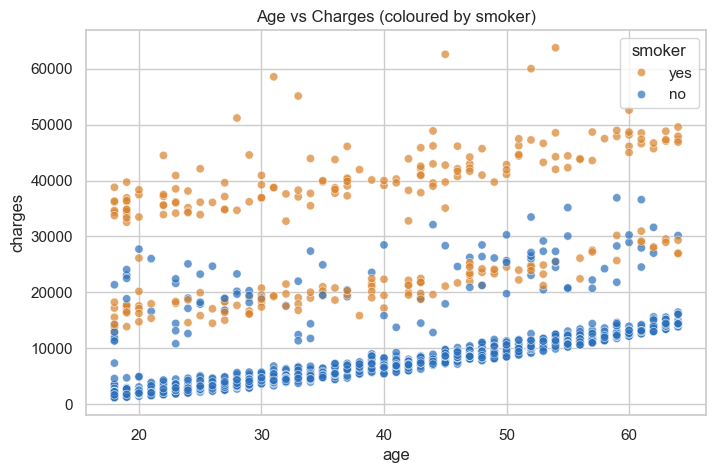

In [121]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df,x="age",y="charges",hue="smoker",palette=SMOKER_COLORS,alpha=0.7)
plt.title("Age vs Charges (coloured by smoker)")
plt.show()

**observation:** Charge increase Steadily with age. We can see three loose bands:non-smokers at the bottom,a middle band,and at the top.This shows that smoking changes the cost a lot at every age.

 **3.3 BMI and Smoking VS Charges**

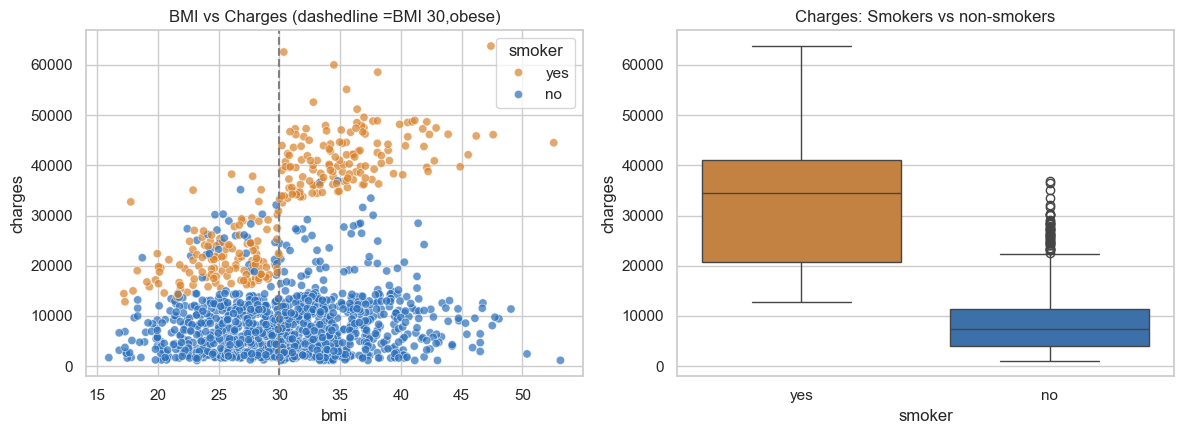

smoker
no      8434.0
yes    32050.0
Name: charges, dtype: float64


In [122]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=df,x="bmi",y="charges",hue="smoker",palette=SMOKER_COLORS,alpha=0.7,ax=ax[0])
ax[0].axvline(x=30, color="gray", linestyle="--")
ax[0].set_title("BMI vs Charges (dashedline =BMI 30,obese)")
sns.boxplot(data=df,x="smoker",y="charges",palette=SMOKER_COLORS,ax=ax[1])
ax[1].set_title("Charges: Smokers vs non-smokers")

plt.tight_layout()
plt.show()

print(df.groupby("smoker")["charges"].mean().round(0))

**observation:** Smoker pay far more than non-smokers on average. For non-smoker,BMI has little effect on charges.
for smokers, charge jump when BMI goes above 30.so **smoking + high BMI together** is the most expensive group.

**3.4 Region and demographic categories**

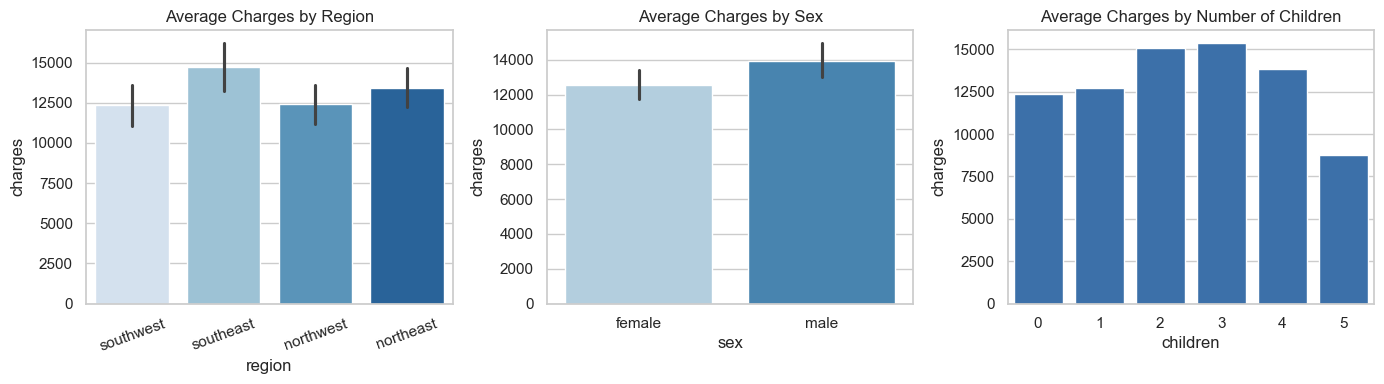

In [123]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.barplot(data=df,x="region",y="charges",palette="Blues",ax=ax[0])
ax[0].set_title("Average Charges by Region")
ax[0].tick_params(axis='x', rotation=20)
sns.barplot(data=df,x="sex",y="charges",palette="Blues",ax=ax[1])
ax[1].set_title("Average Charges by Sex")

sns.barplot(data=df,x="children",y="charges",color=BLUE,errorbar=None,ax=ax[2])
ax[2].set_title("Average Charges by Number of Children")

plt.tight_layout()
plt.show()

In [124]:
print(pd.crosstab(df["region"],df["smoker"],normalize="index").round(2))
print()
print(pd.crosstab(df["sex"],df["smoker"],normalize="index").round(2))

smoker       no   yes
region               
northeast  0.79  0.21
northwest  0.82  0.18
southeast  0.75  0.25
southwest  0.82  0.18

smoker    no   yes
sex               
female  0.83  0.17
male    0.76  0.24


**observation:** Differences across regions, sex and number of children are small compared with the effects of the smoking
Part of the sexand region difference come from the share of smokers in ecah group,not from the group itself.

**3.5 Correlation**

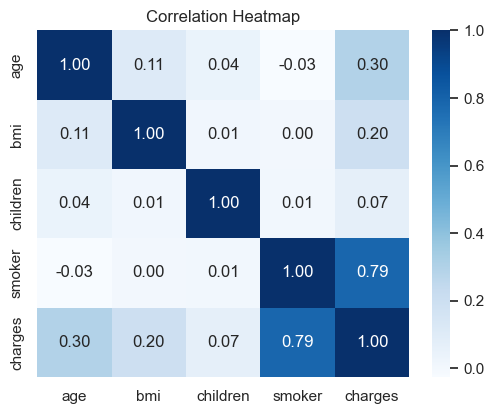

In [125]:
corr_df=df.copy()
corr_df["smoker"]=(corr_df["smoker"]=="yes").astype(int)
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr_df[["age","bmi","children","smoker","charges"]].corr(),annot=True,fmt=".2f",cmap="Blues")
plt.title("Correlation Heatmap")
plt.show()

**observation:** Smoker has the strongest correlation with charges,then age, then bmi.
children has a very weak relationship. Correlation onl measures straigt-line relations,so it understates the smoker + BMI interaction we saw earlier.

## 4. Data Cleaning and Preprocessing

### 4.1 Missing Values and Duplicates

In [126]:
print("Missing Values per column:")
print(df.isnull().sum())

print("\nDuplicates rows:",df.duplicated().sum())
df=df.drop_duplicates().reset_index(drop=True)
print("Shapes after removing dulpicates:",df.shape)

Missing Values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicates rows: 1
Shapes after removing dulpicates: (1337, 7)


#### 4.2 Inconsistent records

In [127]:
for col in ["sex","smoker","region"]:
    df[col]=df[col].str.strip().str.lower()
    print(col,"->",sorted(df[col].unique()))

invalid = df[(df["age"]<18)|(df["age"]>100)|(df["bmi"]<10)|(df["bmi"]>70)|(df["children"]<0)|(df["charges"]<=0)]
print(f"\nInvalid records found: {invalid.shape[0]}")

sex -> ['female', 'male']
smoker -> ['no', 'yes']
region -> ['northeast', 'northwest', 'southeast', 'southwest']

Invalid records found: 0


No missing values and no invalid record were found 

### 4.3 Outliers

age      outliers:    0 (valid range: -9.0 - 87.0)
bmi      outliers:    9 (valid range: 13.7 - 47.3)
charges  outliers:  139 (valid range: -13120.7 - 34524.8)


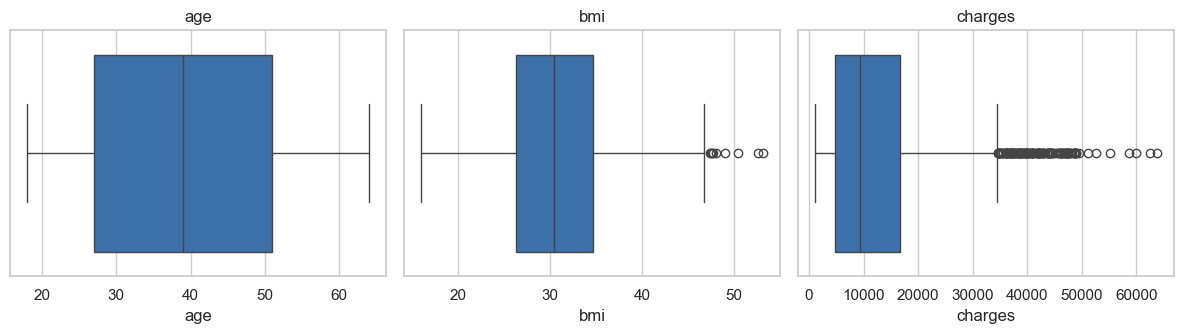

In [128]:
def iqr_bounds(series):
    q1,q3=series.quantile(0.25),series.quantile(0.75)
    iqr=q3-q1
    return q1-1.5*iqr, q3+1.5*iqr
for col in ["age","bmi","charges"]:
    low,high=iqr_bounds(df[col])
    n_out=((df[col]<low)|(df[col]>high)).sum()
    print(f"{col:8s} outliers: {n_out:4d} (valid range: {low:.1f} - {high:.1f})")
fig,ax=plt.subplots(1,3,figsize=(12,3.5))
for i,col in enumerate(["age","bmi","charges"]):
    sns.boxplot(data=df,x=col,color=BLUE,ax=ax[i])
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

**How we handle this outlier**

BMI: a few extreme value exist,so we cap he at the IQR upper limit(winsorizing).This keeps all rows.

Charges:the high values are real, not errors.Removing them woul delete exactly the people we want predict,so we keep them. Tree-based handle them well

In [129]:
low,high=iqr_bounds(df["bmi"])
print("BMI capped to range:",round(low,1),"-",round(high,1))
df["bmi"]=df["bmi"].clip(low,high)
print("New max BMI:",df["bmi"].max())


BMI capped to range: 13.7 - 47.3
New max BMI: 47.31500000000001


## 5. Feature Engineering

New features that are justified by the EDA:

**age_group:** age bands(18-29,30-39,40-49,50-64)

**bmi_category:** stanard WHO group (Underweight,Normal,Overweight,Obese)

**smoker_obses:** 1 if the person is a smoker **and** obese

**smoker_age and smoker_bmi:** interaction feature so even simple linear model can learn that smokers cost grow faster

In [130]:
df["age_group"]=pd.cut(df["age"],bins=[17,29,39,49,64],labels=["18-29","30-39","40-49","50-64"])
df["bmi_category"]=pd.cut(df["bmi"],bins=[0,18.5,25,30,100],labels=["Underweight","Normal","Overweight","Obese"])
df["smoker_flag"]=(df["smoker"]=="yes").astype(int)
df["obese"]=(df["bmi"]>=30).astype(int)
df["smoker_obese"]=df["smoker_flag"]*df["obese"]
df["smoker_age"]=df["smoker_flag"]*df["age"]
df["smoker_bmi"]=df["smoker_flag"]*df["bmi"]

df[["age","age_group","bmi","bmi_category","smoker_flag","obese","smoker_obese","smoker_age","smoker_bmi"]].head(10)

,age,age_group,bmi,bmi_category,smoker_flag,obese,smoker_obese,smoker_age,smoker_bmi
0,19,18-29,27.900,Overweight,1,0,0,19,27.9
1,18,18-29,33.770,Obese,0,1,0,0,0.0
2,28,18-29,33.000,Obese,0,1,0,0,0.0
3,33,30-39,22.705,Normal,0,0,0,0,0.0
4,32,30-39,28.880,Overweight,0,0,0,0,0.0
5,31,30-39,25.740,Overweight,0,0,0,0,0.0
6,46,40-49,33.440,Obese,0,1,0,0,0.0
7,37,30-39,27.740,Overweight,0,0,0,0,0.0
8,37,30-39,29.830,Overweight,0,0,0,0,0.0
9,60,50-64,25.840,Overweight,0,0,0,0,0.0


In [131]:
print(df.groupby("age_group")["charges"].mean().round(0))
print()
print(df.groupby("bmi_category")["charges"].mean().round(0))
print()
print(df.groupby(["smoker", "obese"])["charges"].mean().round(0))

age_group
18-29     9201.0
30-39    11739.0
40-49    14399.0
50-64    17903.0
Name: charges, dtype: float64

bmi_category
Underweight     8658.0
Normal         10435.0
Overweight     10998.0
Obese          15581.0
Name: charges, dtype: float64

smoker  obese
no      0         7977.0
        1         8856.0
yes     0        21363.0
        1        41558.0
Name: charges, dtype: float64


### 5.1 Encoding categorical variables

In [132]:
data = df.copy()
data["sex_male"]=(data["sex"]=="male").astype(int)
data=data.drop(columns=["smoker","sex","obese"])
data=pd.get_dummies(data,columns=["region","age_group","bmi_category"],drop_first=True,dtype=int)
print("shape after encoding:",data.shape)
data.head()

shape after encoding: (1337, 18)


,age,bmi,children,charges,smoker_flag,smoker_obese,smoker_age,smoker_bmi,sex_male,region_northwest,region_southeast,region_southwest,age_group_30-39,age_group_40-49,age_group_50-64,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,27.900,0,16884.92400,1,0,19,27.9,0,0,0,1,0,0,0,0,1,0
1,18,33.770,1,1725.55230,0,0,0,0.0,1,0,1,0,0,0,0,0,0,1
2,28,33.000,3,4449.46200,0,0,0,0.0,1,0,1,0,0,0,0,0,0,1
3,33,22.705,0,21984.47061,0,0,0,0.0,1,1,0,0,1,0,0,1,0,0
4,32,28.880,0,3866.85520,0,0,0,0.0,1,1,0,0,1,0,0,0,1,0


## 6. Train / Test Split

We keep 20% of the data as an untouched test set. It is not used for the feature selection, model selection or tuning.
It us used only once, at the very end

In [133]:
X=data.drop(columns=["charges"])
y=data["charges"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Training rows;",X_train.shape[0],"| Testing rows:",X_test.shape[0])

Training rows; 1069 | Testing rows: 268


### 6.1 Feature selection (using training data only)
We fit a Random Forest on the training set and look at feature importance. Features with importance below 0.4% are dropped. We use a low cut-off because importance is shared between related features (for example `smoker_flag` and its interactions), so a 1% cut-off would wrongly remove useful ones. The age-band and BMI-band columns are mostly repeating information already in `age` and `bmi`.

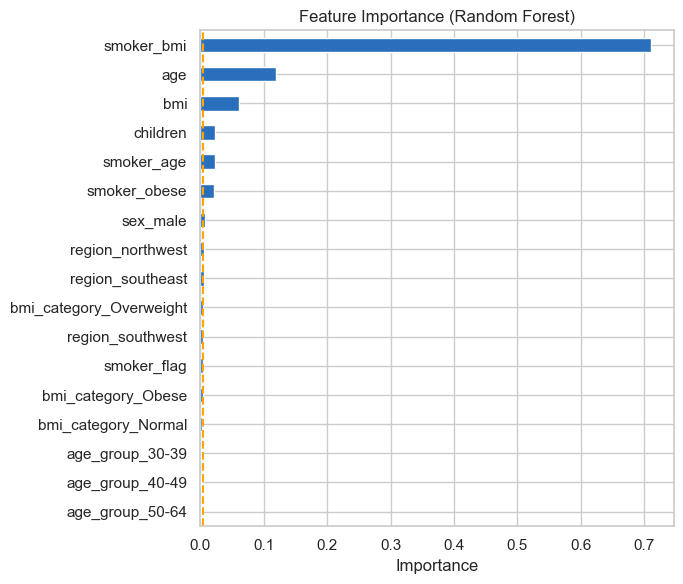

kept  : ['region_southwest', 'bmi_category_Overweight', 'region_southeast', 'region_northwest', 'sex_male', 'smoker_obese', 'smoker_age', 'children', 'bmi', 'age', 'smoker_bmi']
dropped: ['age_group_50-64', 'age_group_40-49', 'age_group_30-39', 'bmi_category_Normal', 'bmi_category_Obese', 'smoker_flag']


In [134]:
rf_check=RandomForestRegressor(n_estimators=200,random_state=42)
rf_check.fit(X_train,y_train)
importance=pd.Series(rf_check.feature_importances_,index=X_train.columns).sort_values()
plt.figure(figsize=(7, 6))
importance.plot(kind="barh",color=BLUE)
plt.axvline(0.004, color="ORANGE", linestyle="--")
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

selected = importance[importance >= 0.004].index.tolist()
dropped=importance[importance < 0.004].index.tolist()
print("kept  :",selected)
print("dropped:",dropped)

X_train=X_train[selected]
X_test=X_test[selected]

## 7. Train and Evaluate Regression Models
We compare four models:
1. **Linear Regression** - simple baseline
2. **Ridge Regression** - linear model with regularization
3. **Random Forest** - many decision trees averaged
4. **Gradient Boosting** - trees built one after another, each fixing the previous errors

In [135]:
def cv_scores(model,X,y):
    res=cross_validate(model,X,y,cv=5,scoring={"mae":"neg_mean_absolute_error","mse":"neg_mean_squared_error","r2":"r2"})
    mse=-res["test_mse"].mean()
    return {"mae":-res["test_mae"].mean(),"mse":mse,"rmse":np.sqrt(mse),"r2":res["test_r2"].mean()}
models={
    "LinearRegression":Pipeline([("scaler",StandardScaler()),("model",LinearRegression())]),
    "Ridge Regression":Pipeline([("scaler",StandardScaler()),("model",Ridge())]),
    "Random Forest":Pipeline([("scaler",StandardScaler()),("model",RandomForestRegressor(random_state=42))]),
    "Gradient Boosting":Pipeline([("scaler",StandardScaler()),("model",GradientBoostingRegressor(random_state=42))])
}

before = {}
for name,model in models.items():
    before[name]=cv_scores(model,X_train,y_train)
before_df=pd.DataFrame(before).T.round(3)
before_df

,mae,mse,rmse,r2
LinearRegression,2420.640,2.051085e+07,4528.891,0.851
Ridge Regression,2419.999,2.051074e+07,4528.878,0.851
Random Forest,2786.425,2.464293e+07,4964.165,0.820
Gradient Boosting,2619.613,2.259718e+07,4753.649,0.835


These are the scores before tuning.MAEand RMSE are in the same unit as charges; lower is better.R**2 is closer to 1 when model explain more the variation

## 8. Hyperparameter tuning (Grid Search + Cross-Validation)
i have used **GridSearchCV** with 5-fold cross-validation, choosing the setting with the lowest MSE.
Linear Regression has no important hyperparameters, so it is left as it is.

In [136]:
param_grids = {
    "Ridge Regression": {"model__alpha": [0.01, 0.1, 1, 10,100]},
    "Random Forest": {"model__n_estimators": [100, 200], "model__max_depth": [3,5,8,None],"model__min_samples_leaf":[1,5,10]},
    "Gradient Boosting": {"model__n_estimators": [50,100,200], "model__max_depth": [2,3,4],"model__learning_rate": [0.05, 0.1]},
}

tuned_models={"LinearRegression":models["LinearRegression"]}
for name,grid in param_grids.items():
    search=GridSearchCV(models[name],grid,cv=5,scoring="neg_mean_squared_error",n_jobs=-1)
    search.fit(X_train,y_train)
    tuned_models[name]=search.best_estimator_
    print(f"{name} best settings={search.best_params_}")


Ridge Regression best settings={'model__alpha': 1}
Random Forest best settings={'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}
Gradient Boosting best settings={'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 50}


In [137]:
after = {}
for name, model in tuned_models.items():
    after[name]=cv_scores(model,X_train,y_train)
after_df=pd.DataFrame(after).T.round(3)
after_df    

,mae,mse,rmse,r2
LinearRegression,2420.640,2.051085e+07,4528.891,0.851
Ridge Regression,2419.999,2.051074e+07,4528.878,0.851
Random Forest,2562.725,2.136552e+07,4622.285,0.845
Gradient Boosting,2613.797,2.120859e+07,4605.279,0.846


### 8.1 Before Vs After tuning

In [138]:
compare=pd.concat({"Before tuning":before_df,"After tuning":after_df},axis=1)
compare

Before tuning                ...                 
                            mae           mse  ...      rmse     r2
LinearRegression       2420.640  2.051085e+07  ...  4528.891  0.851
Ridge Regression       2419.999  2.051074e+07  ...  4528.878  0.851
Random Forest          2786.425  2.464293e+07  ...  4622.285  0.845
Gradient Boosting      2619.613  2.259718e+07  ...  4605.279  0.846

[4 rows x 8 columns]

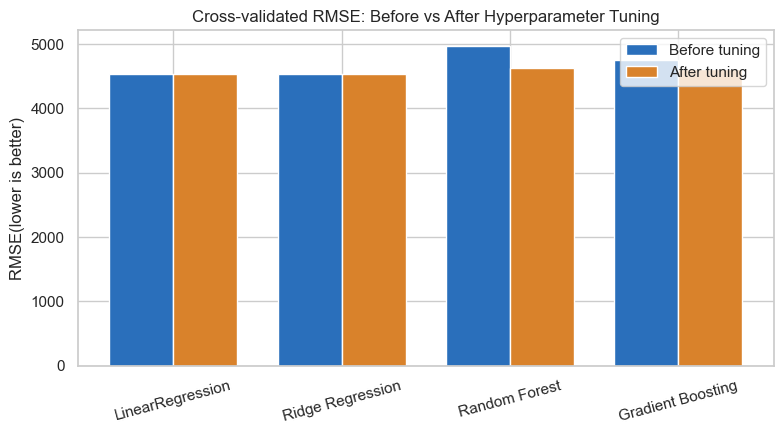

In [139]:
x= np.arange(len(before_df))
width=0.38
plt.figure(figsize=(8, 4.5))
plt.bar(x-width/2,before_df["rmse"],width,label="Before tuning",color=BLUE)
plt.bar(x+width/2,after_df["rmse"],width,label="After tuning",color=ORANGE)
plt.xticks(x,before_df.index,rotation=15)
plt.ylabel("RMSE(lower is better)")
plt.title("Cross-validated RMSE: Before vs After Hyperparameter Tuning")
plt.legend()
plt.tight_layout()
plt.show()

**observation:** Tuning benefits Random Forest and Gradient Boosting the most,while Linear Regression and Ridge show little improvement.After tuning, all models perform similarly,with Ridge slightly leading because the engineered features already capture key patterns

## 9. Final Testing on the Untouched Test set
We pick the tuned model with the lowest cross-validated RMSE,train it on the full training set,and evaluate it once on the test set

In [140]:
best_name=after_df["rmse"].idxmin()
best_model=tuned_models[best_name]
print("Best model:",best_name)

best_model.fit(X_train,y_train)
pred_train=best_model.predict(X_train)
pred_test=best_model.predict(X_test)

def all_matrics(y_true,y_pred):
    mse=mean_squared_error(y_true,y_pred)
    return {"mae":mean_absolute_error(y_true,y_pred),"mse":mse,"rmse":np.sqrt(mse),"r2":r2_score(y_true,y_pred)}
final=pd.DataFrame({"Train":all_matrics(y_train,pred_train),"Test":all_matrics(y_test,pred_test)}).T.round(3)
final

Best model: Ridge Regression


,mae,mse,rmse,r2
Train,2394.397,2.009998e+07,4483.300,0.853
Test,2293.676,1.678960e+07,4097.511,0.909


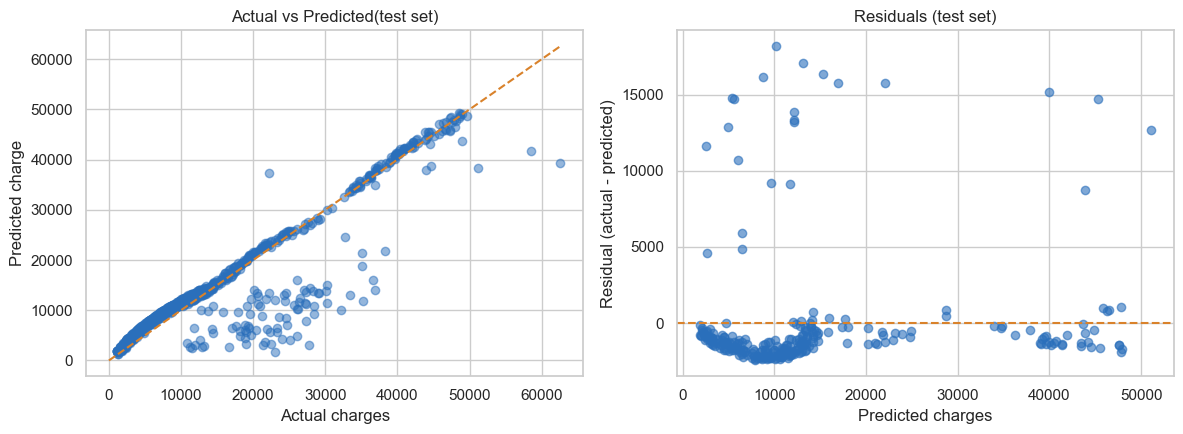

In [141]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
ax[0].scatter(y_train,pred_train,alpha=0.5,color=BLUE)
lims=[0,max(y_train.max(),pred_train.max())]
ax[0].plot(lims,lims,color=ORANGE,linestyle="--")
ax[0].set_xlabel("Actual charges")
ax[0].set_ylabel("Predicted charge")
ax[0].set_title("Actual vs Predicted(test set)")

residuals= y_test - pred_test
ax[1].scatter(pred_test,residuals,alpha=0.6,color=BLUE)
ax[1].axhline(0,color=ORANGE,linestyle="--")
ax[1].set_xlabel("Predicted charges")
ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residuals (test set)")

plt.tight_layout()
plt.show()

Points near the dashed line indicate strong predictive accuracy. The model shows no evidence of the overfitting ,as the training and cross-validation R^2 scores are both approximatesly 0.85.
Althought the test R^2 is slightly higher, the cross validate scores provides a more reliable estimated of real-world performance.Residual analysis suggested that while most prediction errors are small the model tend to underestimate costs for a subset of individuals likely due to unobserved factors not included in the dataset 